# Practice: MNIST Image Classification

Use this practice after Section 8. Complete these activities in order:

- Load and visualise MNIST.
- Train and evaluate with an MLP.
- Train and evaluate with a CNN.
- Compare the results and identify the most frequent digit errors.

[Open in Colab](https://colab.research.google.com/github/wlos/ai_with_python_course/blob/main/16-Deep-Learning-and-Image-Processing/practice/Practice%20MNIST%20Image%20Classification.ipynb)

Run the notebook from top to bottom. The data cell downloads `mnist_train_small.csv` into `sample_data/` in the working directory if it is missing.

Use Colab's standard Python runtime. For local Jupyter, install missing packages with `python -m pip install torch pandas numpy matplotlib scikit-learn`.


## 1 Load and Visualise MNIST

The CSV has no header: column 0 contains the digit target and the remaining 784 columns contain the 28 × 28 greyscale pixels. Divide pixels by 255 to scale them to [0, 1]. Create one stratified 80/20 split for both models, and keep the test data out of training.


Training images: 4,800; test images: 1,200
Flattened training input shape: (4800, 784)


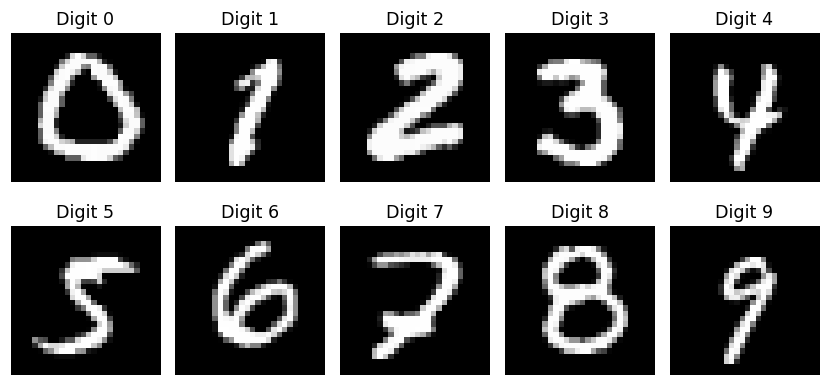

In [1]:
import os
from urllib.request import urlretrieve
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

MNIST_CSV = "sample_data/mnist_train_small.csv"
MNIST_URL = "https://raw.githubusercontent.com/wlos/ai_with_python_course/main/16-Deep-Learning-and-Image-Processing/sample_data/mnist_train_small.csv"
IMAGE_SIDE = 28
RANDOM_STATE = 42
TEST_FRACTION = 0.2

os.makedirs("sample_data", exist_ok=True)
if not os.path.isfile(MNIST_CSV):
    urlretrieve(MNIST_URL, MNIST_CSV + ".part")
    os.replace(MNIST_CSV + ".part", MNIST_CSV)  # Keep only a completed download.

# Load the label column and the 784 pixel columns without a header row.
mnist_data = pd.read_csv(MNIST_CSV, header=None)
digit_labels = mnist_data.iloc[:, 0].to_numpy(dtype="int64")
digit_pixels = mnist_data.iloc[:, 1:].to_numpy(dtype="float32") / 255.0

# Split once so both classifiers use the same training and test images.
train_pixels, test_pixels, train_labels, test_labels = train_test_split(
    digit_pixels, digit_labels, test_size=TEST_FRACTION,
    random_state=RANDOM_STATE, stratify=digit_labels,  # Preserve digit proportions in both sets.
)
print(f"Training images: {len(train_labels):,}; test images: {len(test_labels):,}")
print(f"Flattened training input shape: {train_pixels.shape}")

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for digit, ax in enumerate(axes.ravel()):
    # Reshape one training example per digit for display, without changing model inputs.
    image = train_pixels[train_labels == digit][0].reshape(IMAGE_SIDE, IMAGE_SIDE)
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## 2 Train and Evaluate with an MLP

An MLP treats each image as a vector of 784 pixel features. Use scikit-learn's [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) with the shared `train_pixels`, `test_pixels`, `train_labels` and `test_labels` arrays from Section 1.


### 2.1 Train the MLP

Use one hidden layer with 64 ReLU units and the Adam optimiser. Call `fit(train_pixels, train_labels)` to train the MLP. Scikit-learn manages the weight updates and stopping conditions internally, so no manual training loop is needed.

`max_iter` limits the internal training iterations. `alpha=0.0` disables the MLP's L2 penalty for this example. The test set is not used during training.


In [2]:
from sklearn.neural_network import MLPClassifier
import time

MLP_HIDDEN_UNITS = 64
MLP_BATCH_SIZE = 64
MLP_LEARNING_RATE = 0.001

mlp_model = MLPClassifier(
    hidden_layer_sizes=(MLP_HIDDEN_UNITS,),  # One hidden layer with 64 neurons.
    activation="relu", solver="adam", alpha=0.0,
    batch_size=MLP_BATCH_SIZE, learning_rate_init=MLP_LEARNING_RATE,
    max_iter=200,  # Limit the internal training iterations managed by scikit-learn.
    shuffle=True, random_state=RANDOM_STATE,
)
mlp_start = time.perf_counter()
mlp_model.fit(train_pixels, train_labels)  # Train using only the shared training set.
mlp_training_seconds = time.perf_counter() - mlp_start
print(f"MLP final training loss: {mlp_model.loss_:.4f}")


MLP final training loss: 0.0010


### 2.2 Evaluate the MLP

Use `predict` on the held-out images. Accuracy summarises the fraction classified correctly; macro F1 gives each digit equal weight. The classification report and confusion matrix reveal which digits are confused. Compare training and test accuracy to look for a generalisation gap.

MLP training accuracy: 1.000
MLP test accuracy: 0.940; macro F1: 0.940
              precision    recall  f1-score   support

           0      0.952     0.983     0.967       120
           1      0.991     0.950     0.970       120
           2      0.950     0.950     0.950       120
           3      0.892     0.892     0.892       120
           4      0.918     0.933     0.926       120
           5      0.933     0.925     0.929       120
           6      0.983     0.950     0.966       120
           7      0.950     0.942     0.946       120
           8      0.933     0.933     0.933       120
           9      0.904     0.942     0.922       120

    accuracy                          0.940      1200
   macro avg      0.941     0.940     0.940      1200
weighted avg      0.941     0.940     0.940      1200



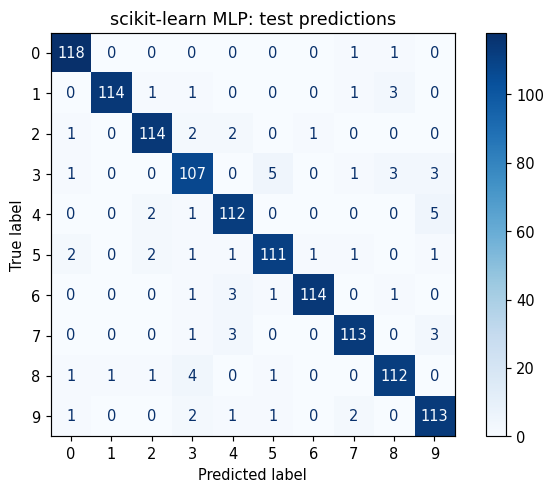

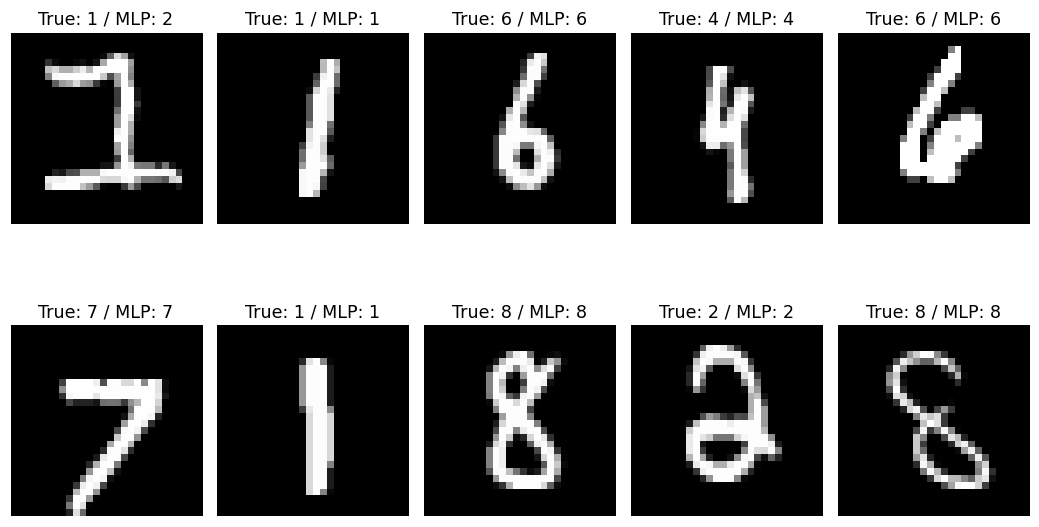

In [3]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

mlp_predictions = mlp_model.predict(test_pixels)  # Predict labels without updating weights.
mlp_train_accuracy = mlp_model.score(train_pixels, train_labels)
mlp_test_accuracy = accuracy_score(test_labels, mlp_predictions)
mlp_macro_f1 = f1_score(test_labels, mlp_predictions, average="macro")
print(f"MLP training accuracy: {mlp_train_accuracy:.3f}")
print(f"MLP test accuracy: {mlp_test_accuracy:.3f}; macro F1: {mlp_macro_f1:.3f}")
print(classification_report(test_labels, mlp_predictions, digits=3, zero_division=0))

# Rows show true classes; columns show predicted classes.
ConfusionMatrixDisplay.from_predictions(test_labels, mlp_predictions, cmap="Blues")
plt.title("scikit-learn MLP: test predictions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 6))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(test_pixels[index].reshape(IMAGE_SIDE, IMAGE_SIDE), cmap="gray")
    ax.set_title(f"True: {test_labels[index]} / MLP: {mlp_predictions[index]}")
    ax.axis("off")
plt.tight_layout(h_pad=3.0)  # Leave room between rows for prediction labels.
plt.show()


## 3 Train and Evaluate with a CNN

Use the same shared training and test arrays from Section 1. The CNN restores the spatial layout of each image instead of using the flattened representation as its model input.

### 3.1 Prepare Image Batches

Reshape the shared pixel arrays into tensors shaped `(batch, 1, 28, 28)` and create data loaders. Shuffle only the training batches. The fixed seed helps reproduce initial weights and batch order; accelerator results can still vary.


In [4]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

CNN_BATCH_SIZE = 64
NUM_CLASSES = 10
HIDDEN_UNITS = 64
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(RANDOM_STATE)  # Seed CNN initial weights.

# Restore the image dimensions and add a single greyscale channel.
cnn_train_images = torch.from_numpy(train_pixels).reshape(-1, 1, IMAGE_SIDE, IMAGE_SIDE)
cnn_test_images = torch.from_numpy(test_pixels).reshape(-1, 1, IMAGE_SIDE, IMAGE_SIDE)
cnn_train_dataset = TensorDataset(cnn_train_images, torch.from_numpy(train_labels))
cnn_test_dataset = TensorDataset(cnn_test_images, torch.from_numpy(test_labels))
cnn_shuffle_generator = torch.Generator().manual_seed(RANDOM_STATE)
cnn_train_loader = DataLoader(
    cnn_train_dataset, batch_size=CNN_BATCH_SIZE, shuffle=True,
    generator=cnn_shuffle_generator,  # Reproduce the training shuffle order.
)
cnn_test_loader = DataLoader(cnn_test_dataset, batch_size=CNN_BATCH_SIZE, shuffle=False)
print(f"Training images: {len(train_labels):,}; test images: {len(test_labels):,}")
print(f"CNN input shape: {tuple(cnn_train_images.shape)}; device: {DEVICE}")


Training images: 4,800; test images: 1,200
CNN input shape: (4800, 1, 28, 28); device: cpu


### 3.2 Define and train the CNN

Two convolution–ReLU–pooling blocks extract spatial features, followed by a 64-unit classifier. The final layer returns raw logits; `CrossEntropyLoss` applies the appropriate log-softmax calculation internally.

For every training batch, clear gradients, calculate the loss, backpropagate and update the weights. Train for five epochs with Adam, batch size 64 and learning rate 0.001. The MLP uses `fit()` to manage training internally; the CNN shows the training loop explicitly.

In [5]:
class SimpleCNN(nn.Module):
    """Extract local image features before fully connected classification."""

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),  # Preserve 28 × 28 spatial size.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Reduce 28 × 28 to 14 × 14.
            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # Learn 32 feature maps.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # Reduce 14 × 14 to 7 × 7.
        )
        pooled_side = IMAGE_SIDE // 4
        self.classifier = nn.Sequential(
            nn.Flatten(),  # Join the 32 feature maps into one vector per image.
            nn.Linear(32 * pooled_side * pooled_side, HIDDEN_UNITS),
            nn.ReLU(),
            nn.Linear(HIDDEN_UNITS, NUM_CLASSES),  # Return one logit for each digit.
        )

    def forward(self, images):
        return self.classifier(self.features(images))


In [6]:
import time

CNN_EPOCHS = 5
CNN_LEARNING_RATE = 0.001
simple_cnn = SimpleCNN().to(DEVICE)  # Move the new model to the selected device.
cnn_loss_function = nn.CrossEntropyLoss()
cnn_optimiser = torch.optim.Adam(simple_cnn.parameters(), lr=CNN_LEARNING_RATE)
cnn_loss_history = []


def synchronise(device):
    """Wait for accelerator work before recording elapsed time."""
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


synchronise(DEVICE)
cnn_start = time.perf_counter()
for epoch in range(CNN_EPOCHS):
    simple_cnn.train()  # Enable training behaviour for this epoch.
    cnn_total_loss = 0.0
    for images, labels in cnn_train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        cnn_optimiser.zero_grad()  # Remove the previous batch's gradients.
        logits = simple_cnn(images)
        loss = cnn_loss_function(logits, labels)
        loss.backward()  # Calculate the parameter gradients.
        cnn_optimiser.step()  # Update model weights using Adam.
        cnn_total_loss += loss.item() * len(labels)
    cnn_epoch_loss = cnn_total_loss / len(cnn_train_dataset)
    cnn_loss_history.append(cnn_epoch_loss)
    print(f"CNN epoch {epoch + 1}/{CNN_EPOCHS}: loss={cnn_epoch_loss:.4f}")
synchronise(DEVICE)
cnn_training_seconds = time.perf_counter() - cnn_start


CNN epoch 1/5: loss=1.2329
CNN epoch 2/5: loss=0.3998
CNN epoch 3/5: loss=0.2813
CNN epoch 4/5: loss=0.2167
CNN epoch 5/5: loss=0.1797


### 3.3 Evaluate the CNN

Switch to evaluation mode and disable gradient tracking. Collect predictions in test-loader order, then calculate the same metrics used for the MLP. The training accuracy below is measured after training has finished.

CNN training accuracy: 0.956
CNN test accuracy: 0.934; macro F1: 0.934
              precision    recall  f1-score   support

           0      0.952     0.983     0.967       120
           1      0.974     0.950     0.962       120
           2      0.966     0.942     0.954       120
           3      0.881     0.925     0.902       120
           4      0.972     0.883     0.926       120
           5      0.919     0.942     0.930       120
           6      0.950     0.942     0.946       120
           7      0.862     0.992     0.922       120
           8      0.940     0.908     0.924       120
           9      0.946     0.875     0.909       120

    accuracy                          0.934      1200
   macro avg      0.936     0.934     0.934      1200
weighted avg      0.936     0.934     0.934      1200



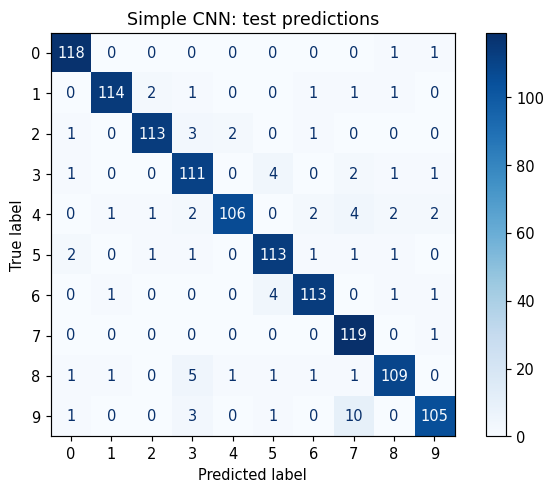

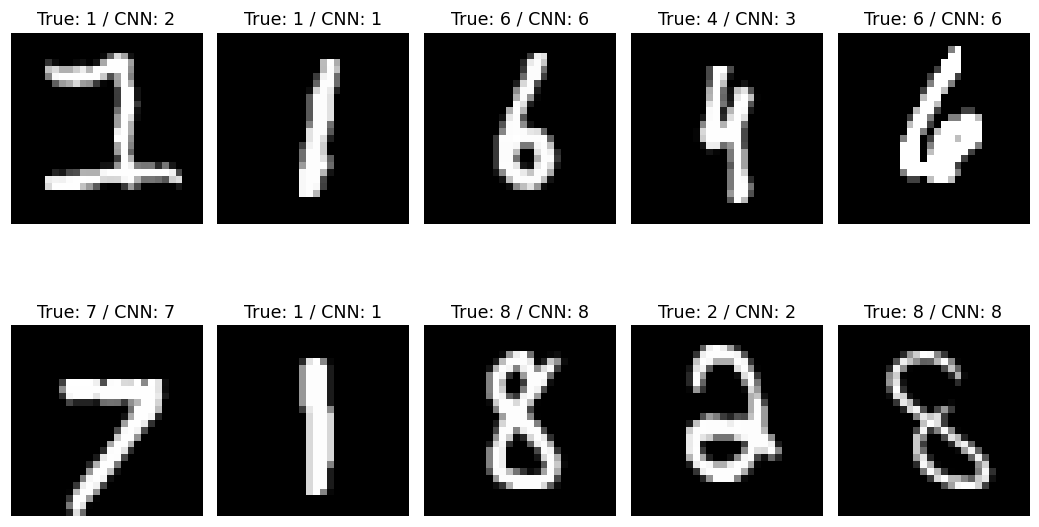

In [7]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay


def cnn_predict(loader):
    """Predict digit labels in loader order without changing the model weights."""
    simple_cnn.eval()
    batches = []
    with torch.no_grad():  # Evaluation does not need parameter gradients.
        for images, _ in loader:
            logits = simple_cnn(images.to(DEVICE))
            batches.append(logits.argmax(dim=1).cpu())
    return torch.cat(batches).numpy()


cnn_predictions = cnn_predict(cnn_test_loader)
# Preserve row order when measuring training accuracy after the final epoch.
cnn_train_eval_loader = DataLoader(cnn_train_dataset, batch_size=CNN_BATCH_SIZE, shuffle=False)
cnn_train_predictions = cnn_predict(cnn_train_eval_loader)
cnn_train_accuracy = accuracy_score(train_labels, cnn_train_predictions)
cnn_test_accuracy = accuracy_score(test_labels, cnn_predictions)
cnn_macro_f1 = f1_score(test_labels, cnn_predictions, average="macro")
print(f"CNN training accuracy: {cnn_train_accuracy:.3f}")
print(f"CNN test accuracy: {cnn_test_accuracy:.3f}; macro F1: {cnn_macro_f1:.3f}")
print(classification_report(test_labels, cnn_predictions, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(test_labels, cnn_predictions, cmap="Blues")
plt.title("Simple CNN: test predictions")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 6))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(cnn_test_images[index, 0].numpy(), cmap="gray")
    ax.set_title(f"True: {test_labels[index]} / CNN: {cnn_predictions[index]}")
    ax.axis("off")
plt.tight_layout(h_pad=3.0)
plt.show()


### 3.4 CPU and GPU Inference Time

Use the trained CNN and a fixed batch of held-out images to time forward passes. Warm-up runs reduce initial setup effects, and synchronisation waits for GPU work to finish. Timing excludes model/data transfer and training. A small model or batch may not benefit from a GPU; a CPU-only environment reports CPU results only.

In [8]:
def time_inference(model, batch, device, repeats):
    """Measure mean forward-pass time after moving the model and data."""
    model = model.to(device)
    batch = batch.to(device)
    model.eval()
    with torch.no_grad():
        for _ in range(3):  # Warm up kernels before starting the timer.
            model(batch)
        synchronise(device)
        start = time.perf_counter()
        for _ in range(repeats):
            model(batch)
        synchronise(device)
    return (time.perf_counter() - start) / repeats


TIMING_BATCH_SIZE = 16
TIMING_REPEATS = 5
cnn_timing_batch = cnn_test_images[:TIMING_BATCH_SIZE]
cnn_devices = ["cpu"]
if torch.cuda.is_available():
    cnn_devices.append("cuda")
elif torch.backends.mps.is_available():
    cnn_devices.append("mps")
cnn_timing_rows = []
for device in cnn_devices:
    seconds = time_inference(simple_cnn, cnn_timing_batch, device, TIMING_REPEATS)
    cnn_timing_rows.append({"device": device, "mean_forward_seconds": seconds})
simple_cnn = simple_cnn.to(DEVICE)  # Restore the model's training device.
pd.DataFrame(cnn_timing_rows)


,device,mean_forward_seconds
0,cpu,0.001062


## 4 Compare the Results

Run both classifiers before this subsection. They use the same shared split from Section 1. Compare test accuracy, macro F1, trainable parameters and training time.

| Feature | scikit-learn MLP | Simple CNN |
|---|---|---|
| Input | 784 flattened pixel values | One 28 × 28 greyscale channel |
| Architecture | 784 → 64 → 10 | Two convolution blocks → 64 → 10 |
| Feature learning | Dense connections between pixel positions | Local shared filters and pooling |
| Trainable parameters | 50,890 | 105,866 |
| Training | scikit-learn `MLPClassifier.fit` | Explicit PyTorch training loop |

Both models use the same 80/20 split, pixel scaling, batch size and learning rate. The MLP uses the stopping conditions managed by `fit()`, while the CNN runs for five epochs. Their training budgets differ. Their architectures, capacities, initialisation and implementation details differ, so this comparison does not isolate convolution as the only cause of any difference. The MLP runs on CPU; the CNN uses the device printed in its workflow. Training times describe this run and are not a hardware benchmark.

In [9]:
# Count weights and biases for each trained model.
mlp_parameter_count = sum(weights.size for weights in mlp_model.coefs_) + sum(
    biases.size for biases in mlp_model.intercepts_
)
cnn_parameter_count = sum(p.numel() for p in simple_cnn.parameters() if p.requires_grad)
comparison_df = pd.DataFrame([
    {"model": "scikit-learn MLP", "training_device": "cpu",
     "train_accuracy": mlp_train_accuracy, "test_accuracy": mlp_test_accuracy,
     "macro_f1": mlp_macro_f1, "parameters": mlp_parameter_count,
     "training_seconds": mlp_training_seconds},
    {"model": "Simple CNN", "training_device": DEVICE,
     "train_accuracy": cnn_train_accuracy, "test_accuracy": cnn_test_accuracy,
     "macro_f1": cnn_macro_f1, "parameters": cnn_parameter_count,
     "training_seconds": cnn_training_seconds},
])
comparison_df


,model,training_device,train_accuracy,test_accuracy,macro_f1,parameters,training_seconds
0,scikit-learn MLP,cpu,1.000000,0.940000,0.940107,50890,2.115129
1,Simple CNN,cpu,0.955833,0.934167,0.934198,105866,5.500346


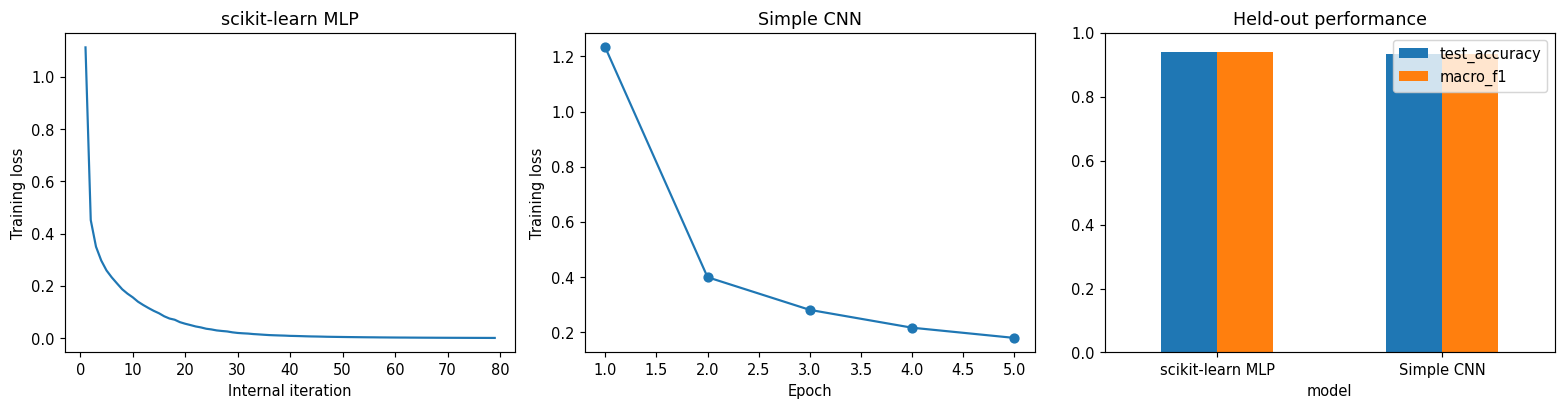

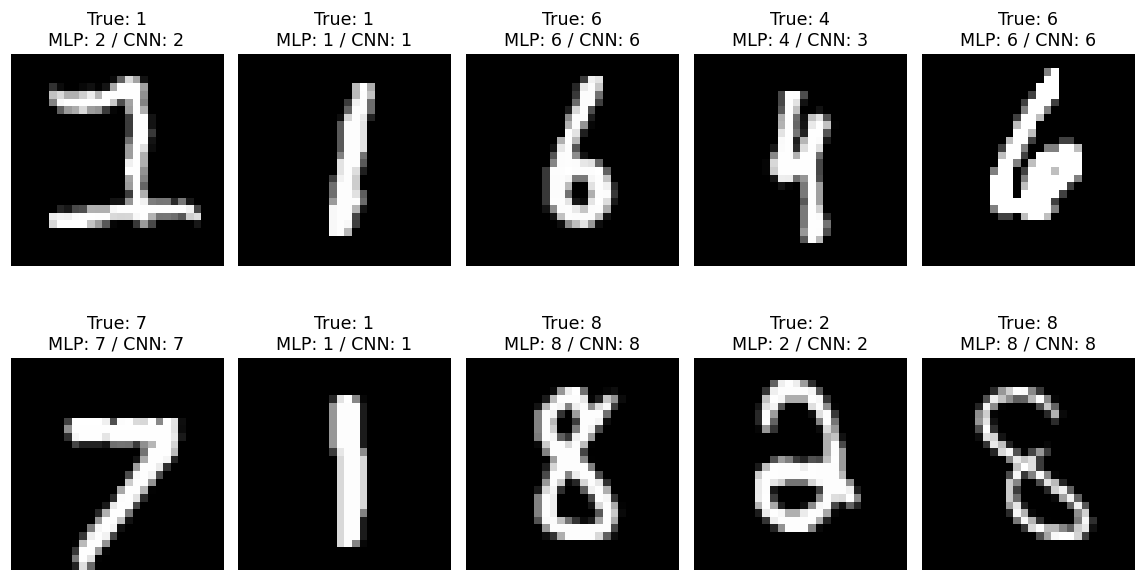

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# Read the MLP loss recorded automatically during fit().
axes[0].plot(range(1, len(mlp_model.loss_curve_) + 1), mlp_model.loss_curve_)
axes[0].set(xlabel="Internal iteration", ylabel="Training loss", title="scikit-learn MLP")
axes[1].plot(range(1, CNN_EPOCHS + 1), cnn_loss_history, marker="o")
axes[1].set(xlabel="Epoch", ylabel="Training loss", title="Simple CNN")
comparison_df.plot.bar(
    x="model", y=["test_accuracy", "macro_f1"], ax=axes[2], rot=0,
    ylim=(0, 1),  # Both scores range from zero to one.
)
axes[2].set_title("Held-out performance")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(11, 6))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(test_pixels[index].reshape(IMAGE_SIDE, IMAGE_SIDE), cmap="gray")
    ax.set_title(
        f"True: {test_labels[index]}\n"
        f"MLP: {mlp_predictions[index]} / CNN: {cnn_predictions[index]}"
    )
    ax.axis("off")
plt.tight_layout(h_pad=3.0)
plt.show()  # Compare both predictions for each of the same test images.


Inspect the confusion matrices and the shared prediction examples. Which digits are difficult for each model? Does higher training accuracy also produce higher test accuracy? Relate the observed results to parameter counts and training time.

For further tuning, create a validation split from the training data and reserve the test set for final evaluation. Change settings only after recording the baseline results.

## 5 Find the most frequent digit errors

Rows of the confusion matrix are true digits and columns are predictions. Predict which two digits each model most often confuses. Run the cell to check the largest off-diagonal count for each model, then compare it with the plotted matrices. If errors tie, the cell shows the first pair in row order.


In [ ]:
from sklearn.metrics import confusion_matrix

for name, predictions in [("MLP", mlp_predictions), ("CNN", cnn_predictions)]:
    errors = confusion_matrix(test_labels, predictions, labels=range(NUM_CLASSES))
    np.fill_diagonal(errors, 0)  # Remove correct predictions before ranking errors.
    actual, predicted = np.unravel_index(errors.argmax(), errors.shape)
    count = errors[actual, predicted]
    if count:
        print(f"{name}: true {actual}, predicted {predicted} ({count} images)")
    else:
        print(f"{name}: all test digits classified correctly")
